# BV-6 with UR-14 dynamical decoupling — a Fig. 1 (bottom) walkthrough

A self-contained replication of **Fig. 1 (bottom)** of Pokharel & Lidar, *"Demonstration of algorithmic
quantum speedup"* (arXiv:2207.07647): the single-shot Bernstein–Vazirani circuit for $n=6$ with
dynamical-decoupling (DD) pulses inserted in every idle gap.

| Goal | Section |
|---|---|
| 1. Replicate the circuit in the figure | §1 |
| 2. Add the UR-14 sequence (Appendix F) | §2, §3 |
| 3. Visualize where the pulses get inserted, like Fig. 1 (bottom) | §4 |
| 4. Understand the flow, the measurement, and why the result is correct | §5 |
| 5. Run it: ideal sim → noisy sim → real hardware | §6, §7 |

This notebook does **not** import `bv_dd_lib.py`. Everything is defined inline so each step can be read
top to bottom. It compares two schedules of the same circuit:

* **`paper`**: the oracle is wrapped in barriers, so all H gates sit at the start and all final H gates at the end.
  Every data qubit waits *in superposition* before **and** after its CNOT, and UR-14 fills both gaps, exactly
  as drawn in Fig. 1 (bottom).
* **`alap`**: Qiskit's default as-late-as-possible schedule with no barriers (what Experiment 1 used).
  Each H is delayed until just before its CNOT, so most of the waiting happens in $|0\rangle$, where DD has nothing to protect.

Each schedule is run bare (`*_free`) and with UR-14 (`*_ur14`) for **all 64 oracles**, which gives 256 circuits in one batch.

In [1]:
import json
import math
import os
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import cm, colors
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.circuit.library import RZGate, XGate
from qiskit.quantum_info import Operator, Statevector
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay, PadDynamicalDecoupling
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator

FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

N = 6                      # data qubits (BV-6), plus one ancilla
HEADLINE = "1" * N         # the oracle drawn in Fig. 1: b = 111111
SEED = 7                   # transpiler seed: layout/routing are reproducible run to run

## 0. Backend

`USE_FAKE_BACKEND = True` runs everything offline against `FakeFez`, a snapshot of `ibm_fez`'s
calibration, qubit connectivity and gate durations. It needs no credentials and uses no QPU time. Set it to
`False` for the real hardware run in §7. Credentials come from the `MY_TOKEN` / `MY_INSTANCE` environment
variables (loaded from `.env` if present), falling back to a previously saved `QiskitRuntimeService`
account. The token is never printed.

In [2]:
USE_FAKE_BACKEND = False
PREFERRED_BACKENDS = ["ibm_fez", "ibm_marrakesh"]


def load_dotenv(path=".env"):
    # Minimal KEY=VALUE loader; existing environment variables win. Values are never printed.
    if not Path(path).exists():
        return
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            key, value = line.split("=", 1)
            os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))


if USE_FAKE_BACKEND:
    from qiskit_ibm_runtime.fake_provider import FakeFez

    service = None
    backend = FakeFez()
else:
    from qiskit_ibm_runtime import QiskitRuntimeService

    load_dotenv()
    token, instance = os.environ.get("MY_TOKEN"), os.environ.get("MY_INSTANCE")
    if token:
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token, instance=instance or None)
    else:
        service = QiskitRuntimeService()  # previously saved account
    available = {b.name for b in service.backends()}
    backend_name = next((name for name in PREFERRED_BACKENDS if name in available), None)
    if backend_name is None:
        raise RuntimeError(f"None of {PREFERRED_BACKENDS} available. Available: {sorted(available)}")
    backend = service.backend(backend_name)

target = backend.target
DT = target.dt                    # seconds per dt sample
DURATIONS = target.durations()    # InstructionDurations, queried in dt


def op_dt(name, qubits):
    # Calibrated duration (dt) of one instruction; virtual/unlisted ones (rz, barrier) are 0.
    try:
        return DURATIONS.get(name, list(qubits))
    except Exception:
        return 0


print(f"Backend: {backend.name}  ({backend.num_qubits} qubits){'  [offline snapshot]' if USE_FAKE_BACKEND else ''}")
print(f"dt = {DT * 1e9:.3f} ns   (the paper's Falcon devices used dt = 2/9 ns)")

qiskit_runtime_service._discover_account:WARNING:2026-09-25 00:16:33,241: Loading account with the given token. A saved account will not be used.


Backend: ibm_fez  (156 qubits)
dt = 4.000 ns   (the paper's Falcon devices used dt = 2/9 ns)


## 1. The ssBV-6 circuit (Fig. 1, top)

The oracle hides a bitstring $b \in \{0,1\}^6$ and computes $f_b(x) = b\cdot x \bmod 2$. The circuit uses
6 data qubits `q0..q5` plus one ancilla `a`:

1. Prepare the ancilla in $|1\rangle$ (X), then H on every qubit.
2. **Oracle**: a CNOT from `q_i` to the ancilla for every `b_i = 1`; `b_i = 0` means identity.
3. H on every data qubit, then measure `q_i` into classical bit `c[i]`.

The barriers mark the "BV Oracle" box from the figure. They also force the schedule used in Fig. 1 (bottom): no
gate can slide across a barrier, so every qubit's first H happens at the start and every final H at the end.

**Bitstring convention**: `b[i]` is data qubit `i`, written left to right (`b = "100000"` marks only `q0`).
There are $2^6 = 64$ possible oracles and all are run. The headline circuit is $b = 111111$, as in Fig. 1.

64 oracles: ['000000', '000001', '000010', '000011'] ... ['111110', '111111']


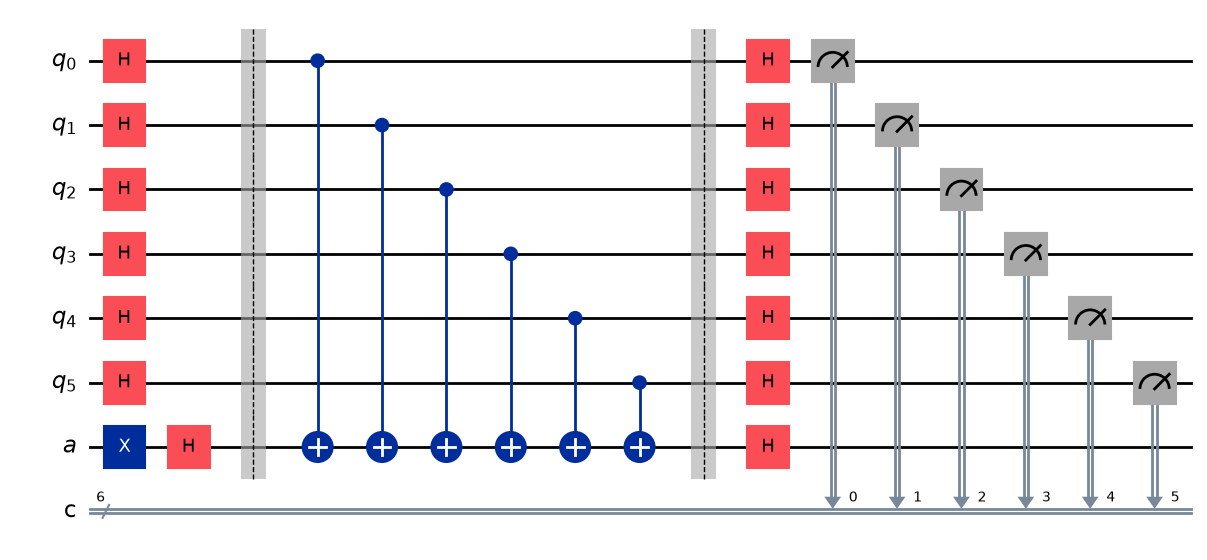

In [3]:
def build_bv(b: str, barriers: bool = True) -> QuantumCircuit:
    n = len(b)
    q = QuantumRegister(n, "q")
    a = QuantumRegister(1, "a")
    c = ClassicalRegister(n, "c")
    qc = QuantumCircuit(q, a, c, name=f"bv_{b}")
    qc.x(a[0])
    qc.h(q)
    qc.h(a[0])
    if barriers:
        qc.barrier()
    for i, bit in enumerate(b):
        if bit == "1":
            qc.cx(q[i], a[0])
    if barriers:
        qc.barrier()
    qc.h(q)
    qc.h(a[0])
    qc.measure(q, c)
    return qc


ORACLES = [format(v, f"0{N}b") for v in range(2**N)]  # all 64, in paper order (q0 = leftmost bit)
print(f"{len(ORACLES)} oracles: {ORACLES[:4]} ... {ORACLES[-2:]}")
build_bv(HEADLINE).draw("mpl", fold=-1)

## 2. The UR-14 sequence (Appendix F)

$\mathrm{UR}n = (\pi)_{\phi_1} - (\pi)_{\phi_2} - \dots - (\pi)_{\phi_n}$, a train of $n$ π-pulses about axes in the
xy-plane at angles

$$\phi_k = \frac{(k-1)(k-2)}{2}\,\Phi^{(n)} + (k-1)\,\phi_2,\qquad
\Phi^{(4m)} = \frac{\pi}{m},\quad \Phi^{(4m+2)} = \frac{2m\pi}{2m+1}.$$

For UR-14, $n = 4\cdot3+2$, so $\Phi = 6\pi/7$.

**One subtlety the appendix doesn't spell out.** The paper sets $\phi_2 = \pi/2$. The whole sequence composes to a
Z-rotation $e^{i\chi Z}$ with $\chi = n\phi_2/2$ (Genov et al. 2017, arXiv:1609.09416), and a DD sequence must compose
to the identity, so $\chi$ must be a multiple of $\pi$.

* For $n = 4m$, $\phi_2 = \pi/2$ works (UR-4 becomes XY4, as the paper says).
* For UR-14, $\phi_2 = \pi/2$ gives $\chi = 7\pi/2$, which is **not** the identity: the sequence would add a
  180° Z-rotation (a phase flip) on every idle qubit it touches.
* $\phi_2 = \Phi$ gives $\chi = 6\pi$, which works.

The cell below checks all three cases numerically.

In [4]:
def ur_big_phi(n: int) -> float:
    if n % 4 == 0:
        return math.pi / (n // 4)
    m = (n - 2) // 4
    return 2 * m * math.pi / (2 * m + 1)


def ur_phases(n: int, phi2: float | None = None) -> list[float]:
    if n < 4 or n % 2:
        raise ValueError("URn needs even n >= 4")
    big_phi = ur_big_phi(n)
    if phi2 is None:
        phi2 = math.pi / 2 if n % 4 == 0 else big_phi  # see the markdown above
    return [((k - 1) * (k - 2) / 2) * big_phi + (k - 1) * phi2 for k in range(1, n + 1)]


def pi_pulse(phi: float) -> np.ndarray:
    # (pi)_phi = exp(-i*pi/2 * (cos(phi) X + sin(phi) Y)) = -i (cos(phi) X + sin(phi) Y)
    return -1j * np.array([[0, np.exp(-1j * phi)], [np.exp(1j * phi), 0]])


def net_z_angle(phases: list[float]) -> float:
    # Multiply the pulses in time order. The product is diagonal, so report its relative phase:
    # arg(U11/U00) = 2*chi, taken mod 2*pi. 0 means identity up to a global phase.
    u = np.eye(2, dtype=complex)
    for phi in phases:
        u = pi_pulse(phi) @ u
    assert abs(u[0, 1]) < 1e-9 and abs(u[1, 0]) < 1e-9, "product should be diagonal"
    return float(np.angle(u[1, 1] / u[0, 0]) % (2 * np.pi))


checks = {
    "UR-4,  phi2 = pi/2  (paper; should be XY4)": ur_phases(4, math.pi / 2),
    "UR-14, phi2 = pi/2  (paper's stated choice)": ur_phases(14, math.pi / 2),
    "UR-14, phi2 = Phi   (used here)": ur_phases(14),
}
for name, ph in checks.items():
    ang = net_z_angle(ph)
    ang = min(ang, 2 * np.pi - ang)  # distance from the identity, 0..180 deg
    print(f"{name:45s} net Z-rotation = {np.degrees(ang):5.1f} deg  -> {'identity' if ang < 1e-9 else 'NOT identity'}")

print("UR-4 axes (deg):", [round(np.degrees(p) % 360) for p in ur_phases(4, math.pi / 2)], "= X, Y, X, Y")
UR14_PHASES = ur_phases(14)
assert min(net_z_angle(UR14_PHASES), 2 * np.pi - net_z_angle(UR14_PHASES)) < 1e-9

UR-4,  phi2 = pi/2  (paper; should be XY4)    net Z-rotation =   0.0 deg  -> identity
UR-14, phi2 = pi/2  (paper's stated choice)   net Z-rotation = 180.0 deg  -> NOT identity
UR-14, phi2 = Phi   (used here)               net Z-rotation =   0.0 deg  -> identity
UR-4 axes (deg): [0, 90, 0, 90] = X, Y, X, Y


### Native-gate form

IBM backends don't have an arbitrary-axis π-pulse gate. We use $(\pi)_\phi = R_Z(\phi)\,X\,R_Z(-\phi)$ instead:
a physical X pulse with a *virtual* frame change on each side. $R_Z$ is zero-duration on IBM hardware, so each
pulse costs exactly one X pulse. Each X is labelled `P1`…`P14`. The transpiler keeps the label, which lets the
timeline in §4 color the pulses the way the paper does.

UR-14 = 42 native gates, 14 physical X pulses; product = identity (up to global phase)
One X pulse = 6 dt = 24 ns  ->  one UR-14 repetition needs >= 84 dt (336 ns) of idle time
Distinct pulse axes (deg) -> pulses: {0.0: ['P1', 'P7', 'P8', 'P14'], 102.9: ['P3', 'P5', 'P10', 'P12'], 154.3: ['P2', 'P6', 'P9', 'P13'], 205.7: ['P4', 'P11']}


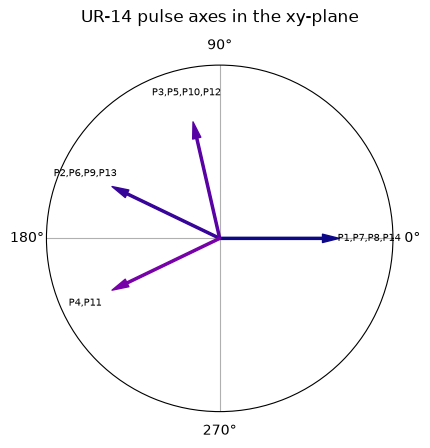

In [5]:
def ur_sequence(phases: list[float]) -> list:
    seq = []
    for k, phi in enumerate(phases, start=1):
        seq += [RZGate(phi), XGate(label=f"P{k}"), RZGate(-phi)]
    return seq


UR14 = ur_sequence(UR14_PHASES)

# The same identity check PadDynamicalDecoupling performs internally, on the actual gate objects.
product = np.eye(2, dtype=complex)
for gate in UR14:
    product = Operator(gate).data @ product
assert Operator(product).equiv(Operator(np.eye(2))), "UR-14 gate list is not the identity"

x_dt = op_dt("x", [0])
print(f"UR-14 = {len(UR14)} native gates, {len(UR14_PHASES)} physical X pulses; product = identity (up to global phase)")
print(f"One X pulse = {x_dt} dt = {x_dt * DT * 1e9:.0f} ns  ->  one UR-14 repetition needs >= {14 * x_dt} dt "
      f"({14 * x_dt * DT * 1e9:.0f} ns) of idle time")

# Mod 360 deg the 14 axes collapse onto only 4 distinct directions; group the pulse labels per axis.
axes_by_angle = defaultdict(list)
for k, phi in enumerate(UR14_PHASES, start=1):
    axes_by_angle[float(round(np.degrees(phi) % 360, 1) % 360)].append(k)
print("Distinct pulse axes (deg) -> pulses:", {a: [f"P{k}" for k in ks] for a, ks in sorted(axes_by_angle.items())})

fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(4.5, 4.5))
cmap_p = plt.get_cmap("plasma", 14)
for angle, ks in axes_by_angle.items():
    phi = np.radians(angle)
    ax.annotate("", xy=(phi, 1), xytext=(0, 0), arrowprops=dict(color=cmap_p(ks[0] - 1), width=1.5, headwidth=6))
    ax.text(phi, 1.25, ",".join(f"P{k}" for k in ks), ha="center", va="center", fontsize=7)
ax.set_yticks([])
ax.set_ylim(0, 1.45)
ax.set_thetagrids([0, 90, 180, 270])
ax.set_title("UR-14 pulse axes in the xy-plane", pad=12)
plt.show()

## 3. Transpile and insert UR-14

**Fixed layout.** The headline circuit ($b=111111$, 6 CNOTs, the hardest one) is transpiled once, and the
physical qubits it picks are reused as `initial_layout` for every oracle and both schedules. All 256 circuits
then run on the same 7 physical qubits, so free-vs-DD and paper-vs-ALAP comparisons aren't mixed up with
differences in qubit quality.

**Routing.** Fez has a heavy-hex layout: the ancilla can reach at most 3 neighbours, so the router adds
SWAPs (the triple-CZ blocks you'll see below). This notebook uses Qiskit's standard Sabre router rather
than the paper's Appendix D ancilla-swap trick. Each CNOT becomes √X/RZ basis changes around a native CZ.

**Scheduling, then DD.** `ALAPScheduleAnalysis` assigns every gate a start time, in dt. Then one of two passes runs:
* `PadDelay` fills each idle gap with an explicit `Delay`, giving the **free** variant.
* `PadDynamicalDecoupling` puts **one repetition of UR-14 into every idle gap long enough to hold it**. It
  stretches the pulse spacing to fill the gap, with τ/2 at both ends and τ between pulses. This is the
  paper's rule: *"one repetition of a pulse sequence that fits precisely in a gap"*. A gap shorter than
  14 X pulses is **left bare**, with no warning. §4 reports these gaps explicitly.

Without barriers, `optimization_level=1` may also cancel the H·H pairs on unmarked qubits. Appendix B shows
this is logically harmless; the barrier ("paper") version keeps them, as the paper does.

In [6]:
SCHEDULES = {"paper": True, "alap": False}      # name -> barriers?
VARIANTS = ["paper_free", "paper_ur14", "alap_free", "alap_ur14"]

headline_isa = generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=SEED).run(
    build_bv(HEADLINE, barriers=True)
)
LAYOUT = headline_isa.layout.initial_index_layout(filter_ancillas=True)  # virtual i -> physical qubit
pm = generate_preset_pass_manager(optimization_level=1, backend=backend, initial_layout=LAYOUT, seed_transpiler=SEED)

free_pm = PassManager([ALAPScheduleAnalysis(target=target), PadDelay(target=target)])
dd_pm = PassManager([ALAPScheduleAnalysis(target=target), PadDynamicalDecoupling(target=target, dd_sequence=UR14)])

# circuits[variant] is a list aligned with ORACLES. Counts are always kept positionally aligned with
# circuit lists and never keyed by circuit name.
circuits = {v: [] for v in VARIANTS}
FINAL_LAYOUT = {}  # circuit name -> physical qubit holding each virtual qubit at the end (scheduling drops .layout)
for b in ORACLES:
    for sched, barriers in SCHEDULES.items():
        isa = pm.run(build_bv(b, barriers=barriers))
        free = free_pm.run(isa)
        free.name = f"bv_{b}_{sched}_free"
        dd = dd_pm.run(isa)
        dd.name = f"bv_{b}_{sched}_ur14"
        circuits[f"{sched}_free"].append(free)
        circuits[f"{sched}_ur14"].append(dd)
        for c in (free, dd):
            FINAL_LAYOUT[c.name] = isa.layout.final_index_layout(filter_ancillas=True)

ROLE = [f"q{i}" for i in range(N)] + ["anc"]
h = ORACLES.index(HEADLINE)
display(pd.DataFrame({"virtual": ROLE, "initial physical": LAYOUT,
                      "physical at measurement": FINAL_LAYOUT[circuits["paper_free"][h].name]}).set_index("virtual").T)

rows = []
for v in VARIANTS:
    c = circuits[v][h]
    ops = c.count_ops()
    dd_pulses = sum(1 for inst in c.data if (inst.operation.label or "").startswith("P"))
    dur = c.estimate_duration(target, unit="dt")
    rows.append({"variant": v, "duration (dt)": dur, "duration (us)": dur * DT * 1e6, "CZ": ops.get("cz", 0),
                 "UR-14 pulses": dd_pulses, "UR-14 repetitions": dd_pulses // 14})
print(f"Headline oracle b = {HEADLINE}:")
display(pd.DataFrame(rows).set_index("variant").round(3))

virtual,q0,q1,q2,q3,q4,q5,anc
initial physical,111,98,109,108,107,118,110
physical at measurement,98,111,110,107,108,118,109


Headline oracle b = 111111:


,duration (dt),duration (us),CZ,UR-14 pulses,UR-14 repetitions
variant,,,,,
paper_free,754,3.016,15,0,0
paper_ur14,754,3.016,15,112,8
alap_free,742,2.968,15,0,0
alap_ur14,742,2.968,15,56,4


## 4. Where the pulses go — the Fig. 1 (bottom) analogue

Qiskit 2.x removed its timeline drawer, so `plot_timeline` draws one from the scheduled circuit. It takes each
instruction's start time from `circuit.op_start_times` and its length from the backend's calibrated durations.
Each row is one physical qubit, labelled with the logical role it starts in; `→` shows where routing SWAPs
moved a logical qubit. The x-axis is in dt (bottom) and µs (top), like the paper's figure.

* grey boxes: √X pulses (H and CNOT basis changes); dark grey: other X gates
* blue: CZ, the native two-qubit gate (a CNOT = CZ plus √X/RZ basis changes; a SWAP is three CNOTs)
* colored: **UR-14 pulses P1…P14**
* dashed red: barriers; white box: measurement

Fig. 1's caption lists four principles. Look for them in the `paper_ur14` panel:
(i) DD fills all available idle gaps, (ii) the pulse spacing adapts to each gap's length,
(iv) a qubit whose idle time is split into separate gaps gets one repetition per gap.
(iii) — different pulse types in different gaps — doesn't apply, because every gap here gets UR-14.

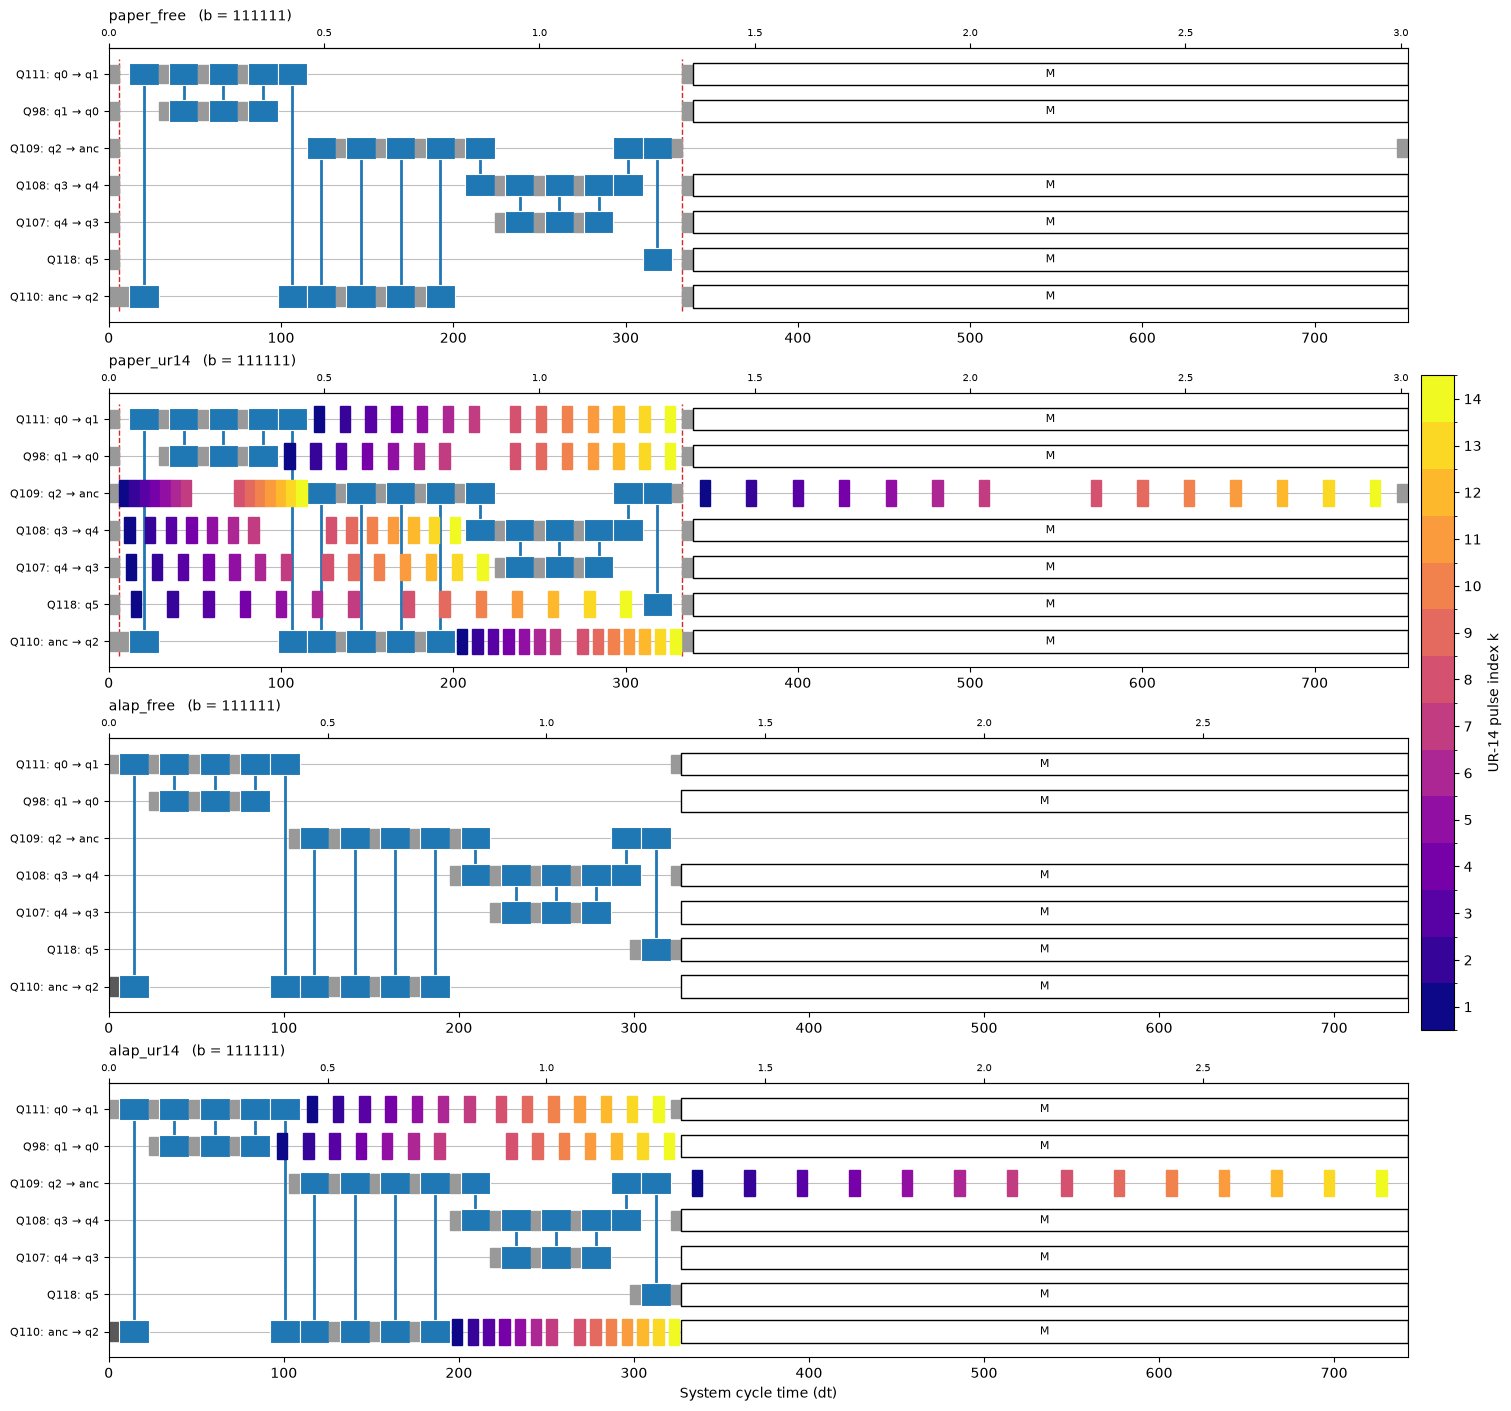

In [7]:
def instructions_with_times(circ):
    for inst, t0 in zip(circ.data, circ.op_start_times):
        qs = [circ.find_bit(q).index for q in inst.qubits]
        name = inst.operation.name
        dur = inst.operation.duration if name == "delay" else op_dt(name, qs)
        yield inst.operation, qs, t0, dur


def row_order(circ):
    active = {q for op, qs, _, _ in instructions_with_times(circ) if op.name not in ("delay", "barrier") for q in qs}
    return list(LAYOUT) + sorted(active - set(LAYOUT))


def row_label(circ, phys):
    fin = FINAL_LAYOUT[circ.name]
    start = ROLE[LAYOUT.index(phys)] if phys in LAYOUT else "routing"
    end = ROLE[fin.index(phys)] if phys in fin else "routing"
    return f"Q{phys}: {start}" + ("" if start == end else f" → {end}")


def plot_timeline(circ, ax, title):
    rows = row_order(circ)
    y = {p: len(rows) - 1 - i for i, p in enumerate(rows)}  # first row at the top
    total = circ.estimate_duration(target, unit="dt")
    for p in rows:
        ax.hlines(y[p], 0, total, color="0.75", lw=0.8, zorder=0)
    for op, qs, t0, dur in instructions_with_times(circ):
        name, label = op.name, op.label or ""
        if name == "barrier":
            ys = [y[q] for q in qs if q in y]
            if ys:
                ax.vlines(t0, min(ys) - 0.4, max(ys) + 0.4, color="tab:red", ls="--", lw=1, zorder=1)
            continue
        if name in ("delay", "rz") or not all(q in y for q in qs):
            continue
        if name == "cz":
            for q in qs:
                ax.add_patch(plt.Rectangle((t0, y[q] - 0.3), dur, 0.6, fc="tab:blue", ec="white", lw=0.8, zorder=2))
            ax.vlines(t0 + dur / 2, min(y[q] for q in qs), max(y[q] for q in qs), color="tab:blue", lw=2, zorder=1)
        elif name == "x" and label.startswith("P"):
            k = int(label[1:])
            ax.add_patch(plt.Rectangle((t0, y[qs[0]] - 0.35), dur, 0.7, color=cmap_p(k - 1), zorder=3))
        elif name == "measure":
            ax.add_patch(plt.Rectangle((t0, y[qs[0]] - 0.3), dur, 0.6, fc="white", ec="k", zorder=2))
            ax.text(t0 + dur / 2, y[qs[0]], "M", ha="center", va="center", fontsize=8, zorder=3, clip_on=True)
        else:  # sx, or a circuit (non-DD) x
            ax.add_patch(plt.Rectangle((t0, y[qs[0]] - 0.25), max(dur, 1), 0.5,
                                       color="0.35" if name == "x" else "0.6", zorder=2))
    ax.set_yticks([y[p] for p in rows], [row_label(circ, p) for p in rows], fontsize=8)
    ax.set_xlim(0, total)
    ax.set_ylim(-0.7, len(rows) - 0.3)
    ax.set_title(title, fontsize=10, loc="left")
    sec = ax.secondary_xaxis("top", functions=(lambda x: x * DT * 1e6, lambda x: x / (DT * 1e6)))
    sec.tick_params(labelsize=7)


fig, axes = plt.subplots(4, 1, figsize=(15, 14), layout="constrained")
for ax, v in zip(axes, VARIANTS):
    plot_timeline(circuits[v][h], ax, f"{v}   (b = {HEADLINE})")
axes[-1].set_xlabel("System cycle time (dt)")
sm = cm.ScalarMappable(cmap=cmap_p, norm=colors.BoundaryNorm(np.arange(0.5, 15.5), 14))
fig.colorbar(sm, ax=axes, ticks=range(1, 15), label="UR-14 pulse index k", shrink=0.5, pad=0.01)
fig.savefig(FIG_DIR / "bv6_timeline_headline.png", dpi=130, bbox_inches="tight")
plt.show()

**Zoom on the oracle.** The measurement is 390 dt long and takes up half the plot above. Here are the two
UR-14 variants cut off at the start of the measurement, with a gate-level Qiskit drawing of `paper_ur14` below.

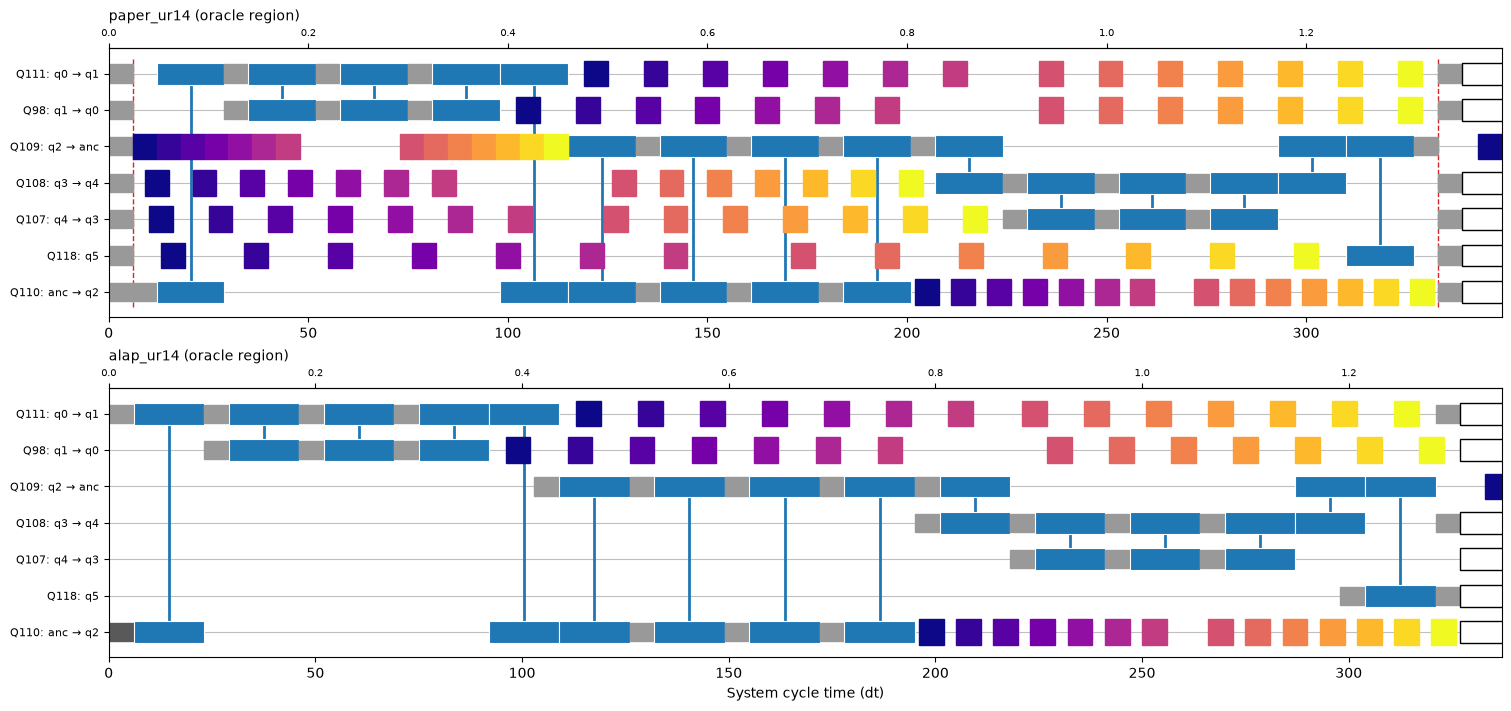

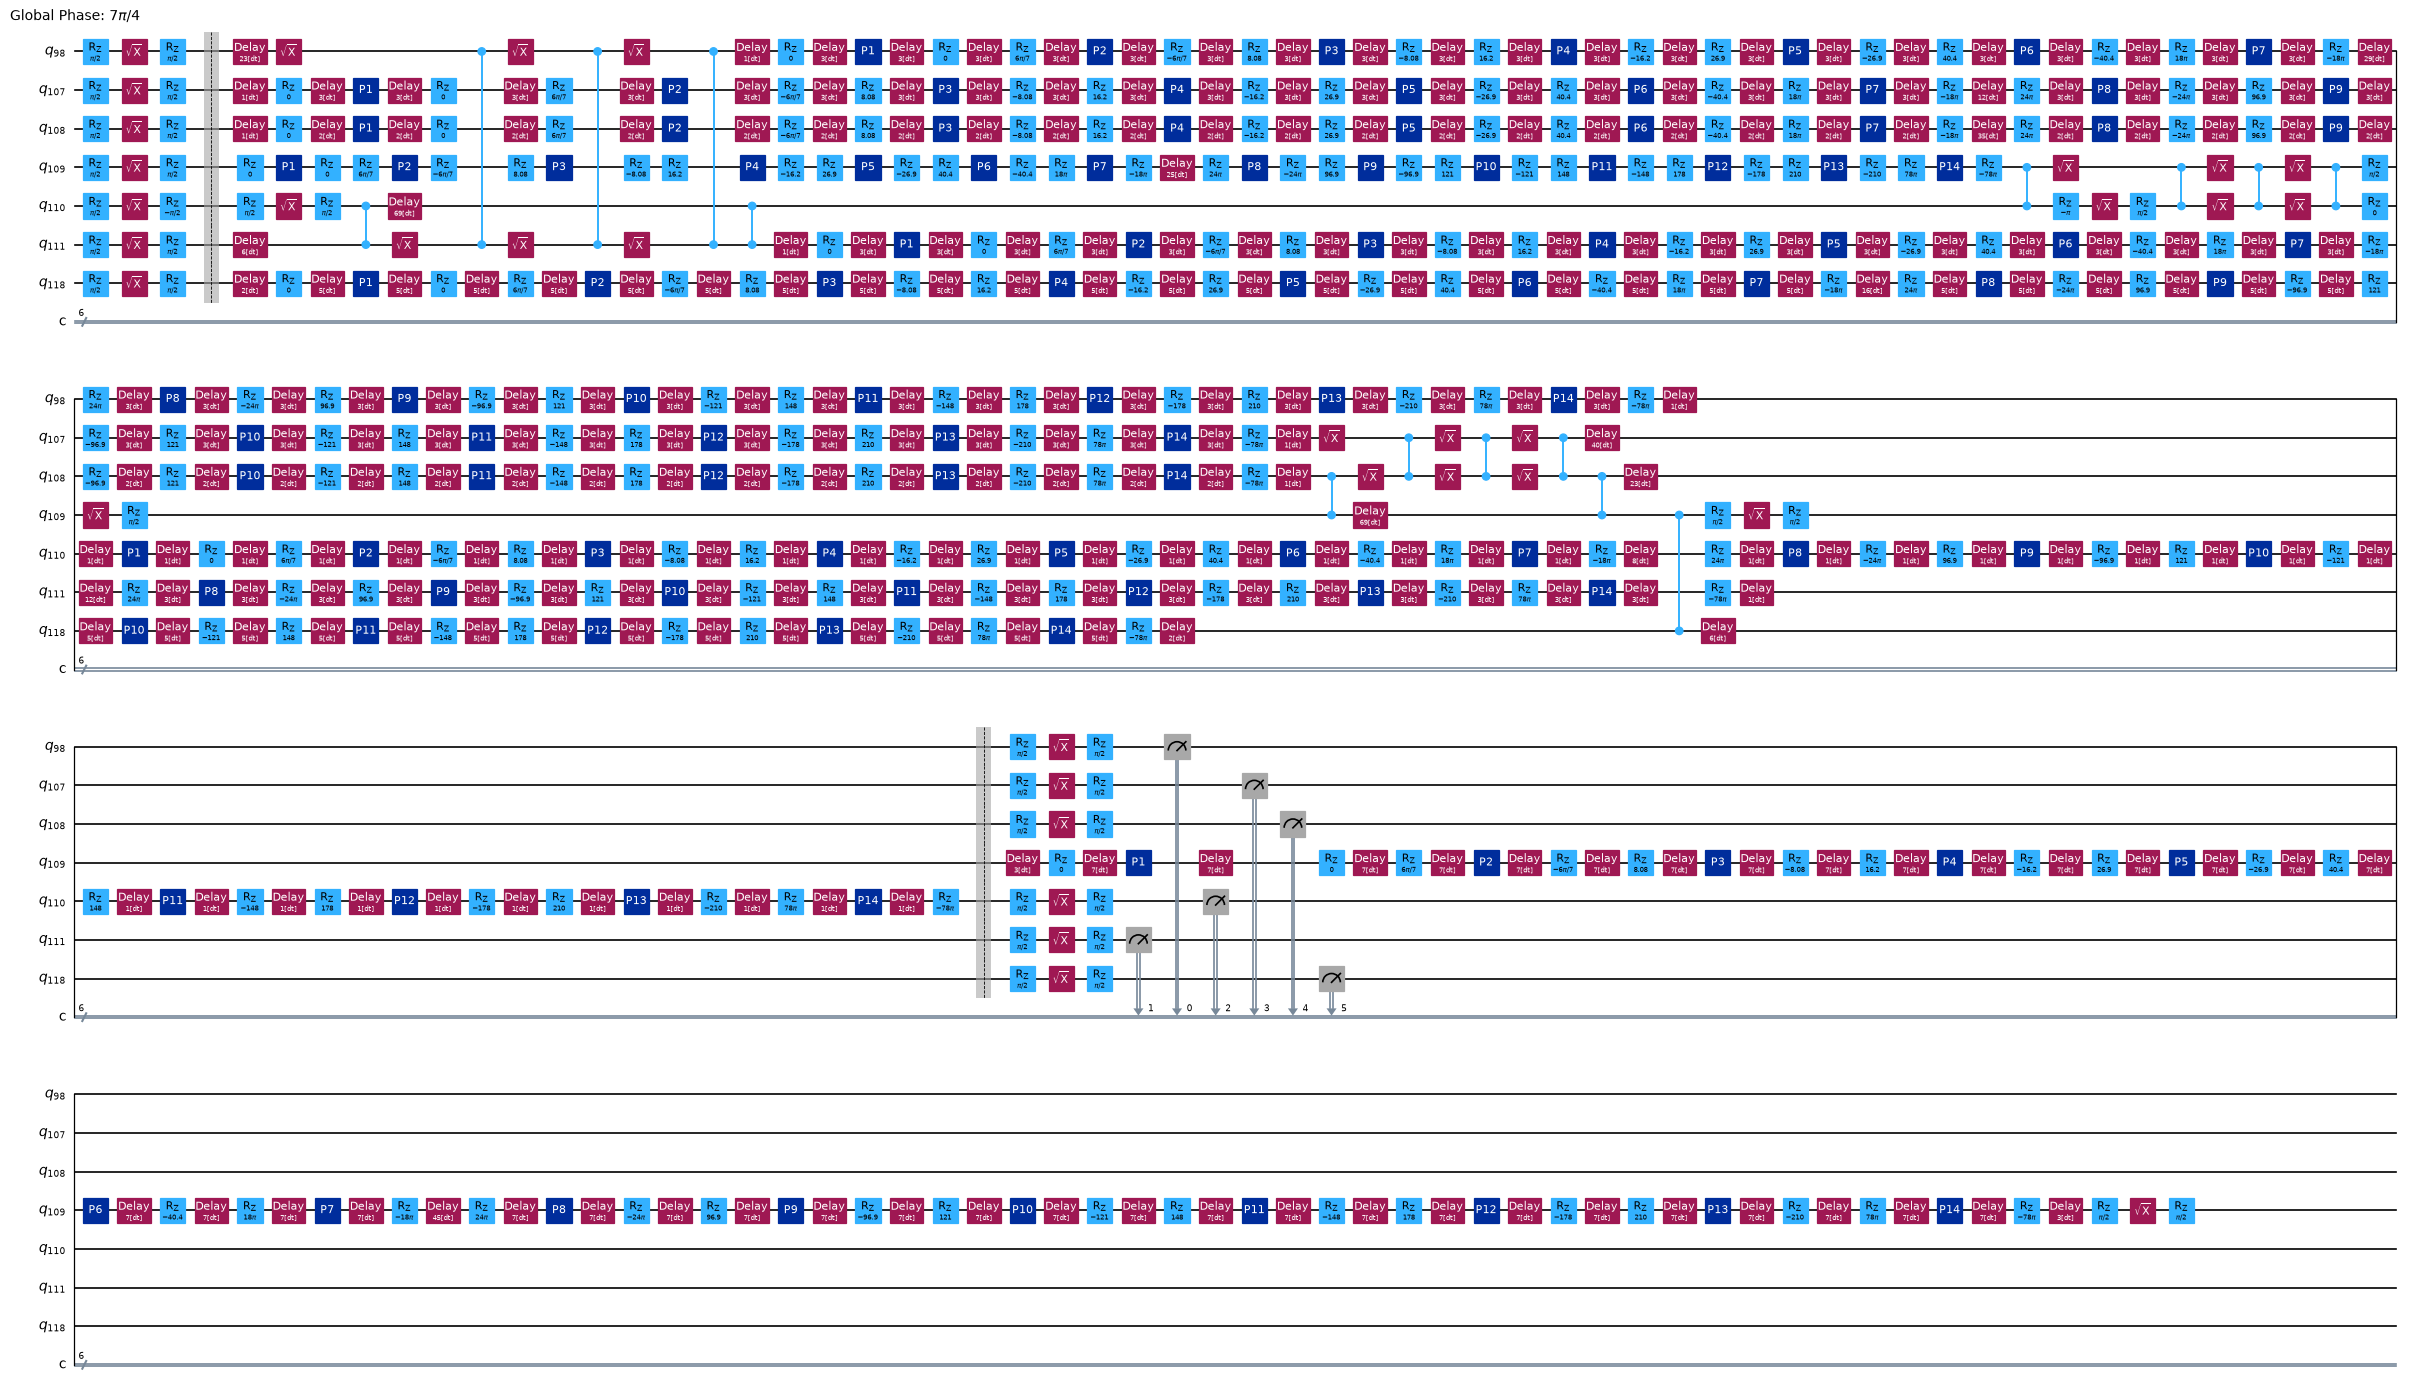

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7), layout="constrained")
for ax, v in zip(axes, ["paper_ur14", "alap_ur14"]):
    c = circuits[v][h]
    plot_timeline(c, ax, f"{v} (oracle region)")
    meas_start = min(t for op, _, t, _ in instructions_with_times(c) if op.name == "measure")
    ax.set_xlim(0, meas_start + 10)
axes[-1].set_xlabel("System cycle time (dt)")
fig.savefig(FIG_DIR / "bv6_timeline_headline_zoom.png", dpi=130, bbox_inches="tight")
plt.show()

circuits["paper_ur14"][h].draw("mpl", idle_wires=False, fold=60, scale=0.6)

### Which idle windows are actually protected?

The timeline shows the pulses; this table counts them. For every idle gap (a `Delay` in the free circuit),
`idle_coverage` records:

* **what state the qubit is in during the gap**:
  * `|0>`: before the qubit's first gate. Nothing to protect: the state is an eigenstate of the dominant
    dephasing/ZZ noise. Qiskit's `skip_reset_qubits=True` deliberately leaves these gaps bare.
  * `superposition`: the qubit is carrying information, so this is where DD matters.
  * `unmeasured tail`: a qubit that is never measured, after its last CZ (e.g. the ancilla after the oracle).
    Errors here can't reach the output.
* **whether UR-14 went in**, and if not, why: the gap was shorter than one repetition (`too short`), or the pass skipped it.

The key number is the **percentage of superposition idle time covered by UR-14**. The `paper` schedule has
far more superposition idle time (qubits wait in $|+\rangle$ before their CNOT), and most of it gets DD. The
`alap` schedule has less to protect, but a smaller share of it is covered. The only gaps left bare are those
shorter than one UR-14 repetition, which are mostly the short waits between consecutive CZs.

In [9]:
def idle_coverage(free, dd):
    seq_dt = {}
    first_gate, last_cz_end, meas_end = {}, defaultdict(int), {}
    for op, qs, t0, dur in instructions_with_times(free):
        if op.name in ("delay", "barrier", "rz"):
            continue
        for q in qs:
            first_gate[q] = min(first_gate.get(q, t0), t0)
            if op.name == "cz":
                last_cz_end[q] = max(last_cz_end[q], t0 + dur)
            if op.name == "measure":
                meas_end[q] = t0 + dur
    dd_starts = defaultdict(list)
    for op, qs, t0, _ in instructions_with_times(dd):
        if op.name == "x" and (op.label or "").startswith("P"):
            dd_starts[qs[0]].append(t0)

    rows = []
    for op, qs, t0, dur in instructions_with_times(free):
        q = qs[0]
        if op.name != "delay" or q not in first_gate or dur == 0:
            continue
        t1 = t0 + dur
        if t1 <= first_gate[q]:
            state = "|0>"
        elif q not in meas_end and t0 >= last_cz_end[q]:
            state = "unmeasured tail"
        elif q in meas_end and t0 >= meas_end[q]:
            state = "after measurement"
        else:
            state = "superposition"
        seq_dt.setdefault(q, 14 * op_dt("x", [q]))
        inserted = any(t0 <= s < t1 for s in dd_starts[q])
        if inserted:
            status = "UR-14 inserted"
        elif state != "superposition":
            status = "no DD needed"
        elif dur < seq_dt[q]:
            status = "too short (bare)"
        else:
            status = "skipped by pass (bare)"
        rows.append({"qubit": row_label(free, q), "start": t0, "end": t1, "length (dt)": dur, "state": state,
                     "UR-14 needs (dt)": seq_dt[q], "status": status})
    return pd.DataFrame(rows)


def coverage_summary(df):
    sup = df[df["state"] == "superposition"]
    total = sup["length (dt)"].sum()
    covered = sup.loc[sup["status"] == "UR-14 inserted", "length (dt)"].sum()
    return {"superposition idle (dt)": total, "covered by UR-14 (dt)": covered,
            "% protected": 100 * covered / total if total else float("nan"),
            "gaps too short": int((sup["status"] == "too short (bare)").sum()),
            "gaps skipped by pass": int((sup["status"] == "skipped by pass (bare)").sum()),
            "|0> idle (dt, unprotected by design)": df.loc[df["state"] == "|0>", "length (dt)"].sum()}


for sched in SCHEDULES:
    cov = idle_coverage(circuits[f"{sched}_free"][h], circuits[f"{sched}_ur14"][h])
    print(f"\n=== {sched} schedule, b = {HEADLINE}: every idle window ===")
    display(cov.sort_values(["qubit", "start"]).set_index(["qubit", "start"]))

summary = {}
for sched in SCHEDULES:
    per_oracle = [coverage_summary(idle_coverage(f, d))
                  for f, d in zip(circuits[f"{sched}_free"], circuits[f"{sched}_ur14"])]
    summary[f"{sched} (b={HEADLINE})"] = per_oracle[h]
    summary[f"{sched} (mean over 64 oracles)"] = pd.DataFrame(per_oracle).mean().to_dict()
display(pd.DataFrame(summary).T.round(1))


=== paper schedule, b = 111111: every idle window ===


end  length (dt)            state  UR-14 needs (dt)  \
qubit          start                                                        
Q107: q4 → q3  6      224          218    superposition                84   
               293    333           40    superposition                84   
Q108: q3 → q4  6      207          201    superposition                84   
               310    333           23    superposition                84   
Q109: q2 → anc 6      115          109    superposition                84   
               224    293           69    superposition                84   
               333    748          415  unmeasured tail                84   
Q110: anc → q2 29      98           69    superposition                84   
               201    333          132    superposition                84   
Q111: q0 → q1  6       12            6    superposition                84   
               115    333          218    superposition                84   
Q118: q5       6      310          304    superposition                84   
               327    333            6    superposition                84   
Q98: q1 → q0   6       29           23    superposition                84   
               98     333          235    superposition                84   

                                status  
qubit          start                    
Q107: q4 → q3  6        UR-14 inserted  
               293    too short (bare)  
Q108: q3 → q4  6        UR-14 inserted  
               310    too short (bare)  
Q109: q2 → anc 6        UR-14 inserted  
               224    too short (bare)  
               333      UR-14 inserted  
Q110: anc → q2 29     too short (bare)  
               201      UR-14 inserted  
Q111: q0 → q1  6      too short (bare)  
               115      UR-14 inserted  
Q118: q5       6        UR-14 inserted  
               327    too short (bare)  
Q98: q1 → q0   6      too short (bare)  
               98       UR-14 inserted


=== alap schedule, b = 111111: every idle window ===


end  length (dt)            state  UR-14 needs (dt)  \
qubit          start                                                        
Q107: q4 → q3  0      218          218              |0>                84   
               287    327           40    superposition                84   
Q108: q3 → q4  0      195          195              |0>                84   
               304    321           17    superposition                84   
Q109: q2 → anc 0      103          103              |0>                84   
               218    287           69    superposition                84   
               321    742          421  unmeasured tail                84   
Q110: anc → q2 23      92           69    superposition                84   
               195    327          132    superposition                84   
Q111: q0 → q1  109    321          212    superposition                84   
Q118: q5       0      298          298              |0>                84   
Q98: q1 → q0   0       23           23              |0>                84   
               92     327          235    superposition                84   

                                status  
qubit          start                    
Q107: q4 → q3  0          no DD needed  
               287    too short (bare)  
Q108: q3 → q4  0          no DD needed  
               304    too short (bare)  
Q109: q2 → anc 0          no DD needed  
               218    too short (bare)  
               321      UR-14 inserted  
Q110: anc → q2 23     too short (bare)  
               195      UR-14 inserted  
Q111: q0 → q1  109      UR-14 inserted  
Q118: q5       0          no DD needed  
Q98: q1 → q0   0          no DD needed  
               92       UR-14 inserted

,superposition idle (dt),covered by UR-14 (dt),% protected,gaps too short,gaps skipped by pass,"|0> idle (dt, unprotected by design)"
paper (b=111111),1653.0,1417.0,85.7,7.0,0.0,0.0
paper (mean over 64 oracles),835.6,684.6,76.9,5.3,0.0,0.0
alap (b=111111),774.0,579.0,74.8,4.0,0.0,837.0
alap (mean over 64 oracles),260.0,172.0,48.0,2.3,0.0,558.2


## 5. Understanding the flow

### 5a. What the state does, step by step

With the ancilla prepared in $|-\rangle$, a CNOT from data qubit $i$ doesn't flip the ancilla at all. Instead it
multiplies the data register's amplitude by $(-1)^{x_i}$ (**phase kickback**). All the marked qubits together
turn the uniform superposition into

$$\frac{1}{8}\sum_x (-1)^{b\cdot x}\,|x\rangle \otimes |-\rangle ,$$

and the final H layer maps that exactly onto $|b\rangle$. So an ideal machine answers with certainty in one
query, while a classical player gets one bit per query. The cell checks each stage with an exact statevector
(logical circuit, no noise, no routing).

b = 111111: after H all amplitudes = +1/8; after oracle sign = (-1)^(b.x) [checked]; after final H: P('111111' as Qiskit key) = 1.000 -> read as b = '111111'
b = 101001: after H all amplitudes = +1/8; after oracle sign = (-1)^(b.x) [checked]; after final H: P('100101' as Qiskit key) = 1.000 -> read as b = '101001'


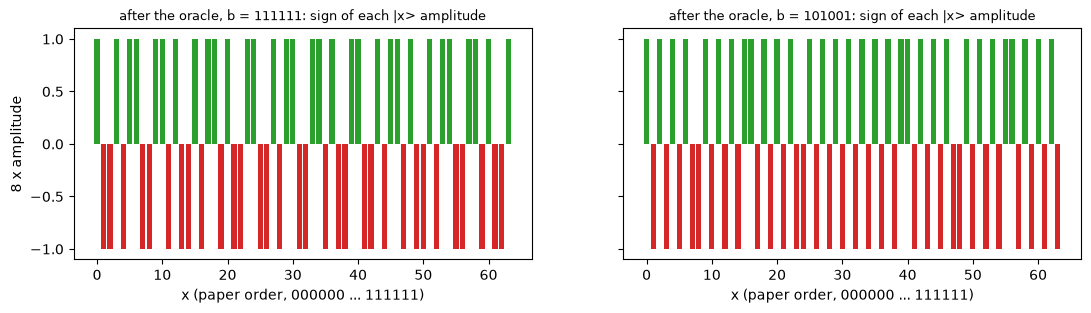

In [10]:
def bv_stage(b: str, stage: int) -> QuantumCircuit:
    # stage 0: after ancilla X | 1: after the H layer | 2: after the oracle | 3: after the final H layer
    q, a = QuantumRegister(N, "q"), QuantumRegister(1, "a")
    qc = QuantumCircuit(q, a)
    qc.x(a[0])
    if stage >= 1:
        qc.h(q)
        qc.h(a[0])
    if stage >= 2:
        for i, bit in enumerate(b):
            if bit == "1":
                qc.cx(q[i], a[0])
    if stage >= 3:
        qc.h(q)
        qc.h(a[0])
    return qc


def data_amplitudes(sv: Statevector) -> np.ndarray:
    # Data-register amplitudes with the ancilla (qubit N, most significant) factored out as |->,
    # indexed by x in paper order (q0 = leftmost bit).
    psi = sv.data.reshape(2, 2**N)  # [ancilla bit, data index (little-endian)]
    assert np.allclose(psi[0], -psi[1]), "ancilla should be in |->"
    amps = (psi[0] - psi[1]) / math.sqrt(2)
    return np.array([amps[int(x[::-1], 2)] for x in ORACLES])


fig, axes = plt.subplots(1, 2, figsize=(13, 3), sharey=True)
for ax, b in zip(axes, [HEADLINE, "101001"]):
    after_h = data_amplitudes(Statevector(bv_stage(b, 1)))
    after_oracle = data_amplitudes(Statevector(bv_stage(b, 2)))
    expected = np.array([(-1) ** sum(int(bi) * int(xi) for bi, xi in zip(b, x)) for x in ORACLES]) / 8
    assert np.allclose(after_h, 1 / 8) and np.allclose(after_oracle, expected)
    final = Statevector(bv_stage(b, 3)).probabilities_dict(qargs=list(range(N)))
    top = max(final, key=final.get)
    print(f"b = {b}: after H all amplitudes = +1/8; after oracle sign = (-1)^(b.x) [checked]; "
          f"after final H: P('{top}' as Qiskit key) = {final[top]:.3f} -> read as b = '{top[::-1]}'")
    ax.bar(range(64), np.real(after_oracle) * 8, color=np.where(np.real(after_oracle) > 0, "tab:green", "tab:red"))
    ax.set_title(f"after the oracle, b = {b}: sign of each |x> amplitude", fontsize=9)
    ax.set_xlabel("x (paper order, 000000 ... 111111)")
axes[0].set_ylabel("8 x amplitude")
plt.show()

### 5b. How the measurement is read

* `measure(q[i], c[i])` ties classical bit `c[i]` to **logical** qubit `q_i`. The transpiler keeps that tie
  through routing: the measurement goes on whichever physical qubit holds `q_i` at the end (the "physical at
  measurement" row in §3). SWAPs therefore never scramble the answer.
* Qiskit prints count keys **little-endian**, i.e. `c5 c4 c3 c2 c1 c0`, so the key for oracle $b$ is `b[::-1]`.
  Example: $b = 100000$ (only `q0` marked) comes back as `'000001'`.
* **Success probability**, the paper's figure of merit: $p_s(b) = \text{counts}[b^{\text{rev}}]/\text{shots}$.
  Reference points:
  * $1/64$: a classical single-shot random guess.
  * $1/2$: if $p_s > 1/2$, majority vote over repetitions reaches the 2/3 BQP bound (the paper's green vs. red dots).
  * The paper reports averages and error bars at **5σ**, with binomial $\sigma=\sqrt{p(1-p)/\text{shots}}$. We do the same.

In [11]:
def expected_key(b: str) -> str:
    return b[::-1]


def success_prob(counts: dict, b: str) -> float:
    return counts.get(expected_key(b), 0) / sum(counts.values())


def split_by_variant(counts_list: list[dict]) -> dict[str, list[dict]]:
    # Inverse of ALL_CIRCUITS below: block-wise, one block of 64 per variant, in ORACLES order.
    n = len(ORACLES)
    return {v: counts_list[i * n:(i + 1) * n] for i, v in enumerate(VARIANTS)}


ALL_CIRCUITS = [c for v in VARIANTS for c in circuits[v]]
print(f"{len(ALL_CIRCUITS)} circuits in one batch ({len(VARIANTS)} variants x {len(ORACLES)} oracles)")

demo = AerSimulator().run(circuits["paper_free"][ORACLES.index("100000")], shots=100).result().get_counts()
print("b = 100000 -> ideal counts", demo, "-> expected key", expected_key("100000"))

256 circuits in one batch (4 variants x 64 oracles)
b = 100000 -> ideal counts {'000001': 100} -> expected key 000001


### 5c. Correctness gates

These must pass before any hardware run. A failure here means the construction is wrong. It does *not* mean DD failed.

1. **UR-14 is the identity** (checked in §2).
2. **DD only fills idle time.** Every UR-14 circuit has the same total duration as its free twin, and every
   non-DD gate (√X, CZ, measure) starts at exactly the same time.
3. **Ideal simulation gives $p_s = 1$ exactly** for all 256 circuits. The routed, scheduled, DD-padded
   circuits still compute $|b\rangle$.

In [12]:
def fixed_gate_times(circ):
    return sorted((op.name, tuple(qs), t0) for op, qs, t0, _ in instructions_with_times(circ)
                  if op.name in ("sx", "cz", "measure") or (op.name == "x" and not (op.label or "").startswith("P")))


for sched in SCHEDULES:
    for free, dd in zip(circuits[f"{sched}_free"], circuits[f"{sched}_ur14"]):
        assert free.estimate_duration(target, unit="dt") == dd.estimate_duration(target, unit="dt"), free.name
        assert fixed_gate_times(free) == fixed_gate_times(dd), free.name
print("Gate 2 passed: DD changed no durations and moved no circuit gate (128 free/UR-14 pairs).")

ideal = split_by_variant(AerSimulator().run(ALL_CIRCUITS, shots=500, seed_simulator=SEED).result().get_counts())
ideal_ps = pd.DataFrame({v: [success_prob(c, b) for c, b in zip(ideal[v], ORACLES)] for v in VARIANTS}, index=ORACLES)
assert (ideal_ps == 1.0).all().all(), ideal_ps[(ideal_ps < 1).any(axis=1)]
print("Gate 3 passed: ideal p_s = 1.000 for all", ideal_ps.size, "circuits.")

Gate 2 passed: DD changed no durations and moved no circuit gate (128 free/UR-14 pairs).
Gate 3 passed: ideal p_s = 1.000 for all 256 circuits.


### 5d. Why DD helps: a deterministic toy-noise demo

A superconducting qubit's frequency drifts slowly, and it picks up a Z-rotation from the static ZZ coupling to its
neighbours. Over one shot this acts like a **static detuning** $\Delta f$: during an idle gap of length $t$ the qubit
rotates by $R_Z(2\pi\,\Delta f\,t)$.

Below, that rotation is added after every `Delay` in the scheduled circuits and the result is run noiselessly:

* **free**: every superposition gap accumulates phase, and the final H turns that phase into bit flips.
* **UR-14**: the delays *between* pulses also rotate, but each π-pulse flips the sign of $Z$, so the phases cancel
  within each gap (a generalized spin echo). Only the gaps left bare in §4 still pick up error.
* A $|0\rangle$ gap doesn't care about Z at all. That is why `alap_free` holds up better than `paper_free` here:
  it spends most of its waiting in $|0\rangle$.

This is a cartoon of real noise: no T1, no pulse errors. It isolates the mechanism the paper relies on.

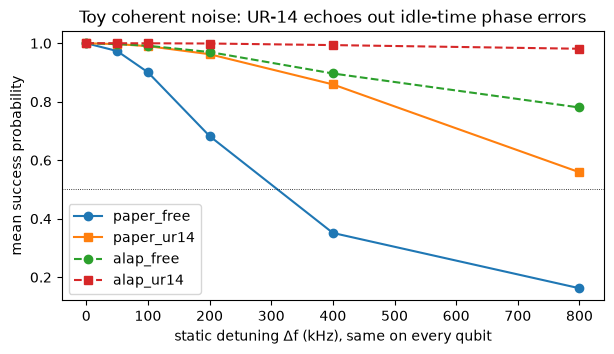

variant,paper_free,paper_ur14,alap_free,alap_ur14
detuning (kHz),,,,
0,1.000,1.000,1.000,1.000
50,0.973,0.997,0.997,1.000
100,0.901,0.990,0.991,1.000
200,0.683,0.962,0.970,0.999
400,0.351,0.859,0.897,0.994
800,0.162,0.559,0.780,0.981


In [13]:
def with_detuning(circ: QuantumCircuit, delta_f_hz: float) -> QuantumCircuit:
    out = circ.copy_empty_like()
    for inst in circ.data:
        out.append(inst)
        if inst.operation.name == "delay":
            out.rz(2 * np.pi * delta_f_hz * inst.operation.duration * DT, inst.qubits[0])
    return out


DETUNINGS_KHZ = [0, 50, 100, 200, 400, 800]
demo_oracles = list(range(0, 64, 4)) + [h]  # 17 oracles incl. the headline, to keep this cell quick
sim = AerSimulator()
demo_rows = []
for df_khz in DETUNINGS_KHZ:
    batch = [with_detuning(circuits[v][i], df_khz * 1e3) for v in VARIANTS for i in demo_oracles]
    counts = sim.run(batch, shots=400, seed_simulator=SEED).result().get_counts()
    for j, v in enumerate(VARIANTS):
        block = counts[j * len(demo_oracles):(j + 1) * len(demo_oracles)]
        ps = [success_prob(c, ORACLES[i]) for c, i in zip(block, demo_oracles)]
        demo_rows.append({"detuning (kHz)": df_khz, "variant": v, "mean p_s": np.mean(ps), f"p_s(b={HEADLINE})": ps[-1]})
demo_df = pd.DataFrame(demo_rows)

fig, ax = plt.subplots(figsize=(7, 3.5))
for v, style in zip(VARIANTS, ["-o", "-s", "--o", "--s"]):
    d = demo_df[demo_df["variant"] == v]
    ax.plot(d["detuning (kHz)"], d["mean p_s"], style, label=v)
ax.set_xlabel("static detuning Δf (kHz), same on every qubit")
ax.set_ylabel("mean success probability")
ax.set_title("Toy coherent noise: UR-14 echoes out idle-time phase errors")
ax.axhline(0.5, color="k", lw=0.6, ls=":")
ax.legend()
plt.show()
display(demo_df.pivot(index="detuning (kHz)", columns="variant", values="mean p_s")[VARIANTS].round(3))

## 6. Results helpers (used for both the noisy rehearsal and the hardware run)

* `ps_table`: $p_s$ for every oracle and variant.
* `plot_fig2`: the paper's Fig. 2. Each row is an oracle $b$, each column a detected bitstring (both in paper
  order), and the color is the frequency. Diagonal dots are green if $p_s > 1/2$ and red otherwise.
* `summary_table`: average $p_s \pm 5\sigma$ and the number of oracles above ½, per variant.

For reference, the paper's BV-6 figure reports an average of **59.9 ± 0.4%** without DD and **74.7 ± 0.3%** with DD.

In [14]:
PAPER_REF = {"without DD": 0.599, "with DD": 0.747}


def ps_table(counts_by_variant: dict[str, list[dict]], shots: int) -> pd.DataFrame:
    df = pd.DataFrame({v: [success_prob(c, b) for c, b in zip(counts_by_variant[v], ORACLES)] for v in VARIANTS},
                      index=pd.Index(ORACLES, name="oracle b"))
    df.insert(0, "weight", [b.count("1") for b in ORACLES])
    return df


def summary_table(ps: pd.DataFrame, shots: int) -> pd.DataFrame:
    rows = []
    for v in VARIANTS:
        p = ps[v].to_numpy()
        sigma_mean = np.sqrt(np.sum(p * (1 - p) / shots)) / len(p)
        rows.append({"variant": v, "mean p_s": p.mean(), "±5σ": 5 * sigma_mean, "min p_s": p.min(),
                     "oracles with p_s > 1/2": int((p > 0.5).sum())})
    return pd.DataFrame(rows).set_index("variant")


def plot_fig2(counts_by_variant: dict[str, list[dict]], ps: pd.DataFrame, title: str, fname: str):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5.2), sharey=True, layout="constrained")
    for ax, v in zip(axes, VARIANTS):
        grid = np.zeros((64, 64))
        for row, counts in enumerate(counts_by_variant[v]):
            total = sum(counts.values())
            for key, cnt in counts.items():
                grid[row, int(key[::-1], 2)] += cnt / total  # Qiskit key -> paper order
        im = ax.imshow(grid, cmap="viridis", vmin=0, vmax=1, origin="lower")
        good = ps[v].to_numpy() > 0.5
        ax.scatter(np.arange(64)[good], np.arange(64)[good], s=6, c="lime", label="p_s > 1/2")
        ax.scatter(np.arange(64)[~good], np.arange(64)[~good], s=6, c="red", label="p_s ≤ 1/2")
        ax.set_title(f"{v}: mean p_s = {ps[v].mean():.3f}", fontsize=10)
        ax.set_xlabel("detected bitstring (as integer)")
    axes[0].set_ylabel("oracle b (as integer)")
    axes[0].legend(loc="upper left", fontsize=7)
    fig.colorbar(im, ax=axes, shrink=0.8, label="frequency")
    fig.suptitle(title)
    fig.savefig(FIG_DIR / fname, dpi=120, bbox_inches="tight")
    plt.show()


def plot_ps_vs_weight(ps: pd.DataFrame, shots: int, title: str):
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for v, style in zip(VARIANTS, ["-o", "-s", "--o", "--s"]):
        g = ps.groupby("weight")[v]
        mean = g.mean()
        err = 5 * np.sqrt(g.apply(lambda p: np.sum(p * (1 - p) / shots)) ) / g.size()
        ax.errorbar(mean.index, mean.values, yerr=err.values, fmt=style, capsize=3, label=v)
    ax.axhline(0.5, color="k", lw=0.6, ls=":")
    ax.set_xlabel("Hamming weight of b (= number of CNOTs in the oracle)")
    ax.set_ylabel("mean p_s  (±5σ)")
    ax.set_title(title)
    ax.legend()
    plt.show()

## 7. Run it

### 7a. Noisy local rehearsal (no QPU time)

`AerSimulator.from_backend` builds a noise model from the backend's calibration: T1/T2 relaxation (idle time
included), depolarizing gate errors and readout errors. It has **no ZZ crosstalk and no slow frequency drift**,
which are the coherent errors DD mostly exists to suppress. Any free-vs-UR-14 difference here comes from how
the pulses interact with Markovian T1/T2 and gate errors, so read it as a sanity check rather than a prediction.
This step is a dress rehearsal of the whole data path (batching → counts → $p_s$ → plots). The DD question
itself can only be answered on hardware (§7c).

,mean p_s,±5σ,min p_s,oracles with p_s > 1/2
variant,,,,
paper_free,0.9015,0.0059,0.846,64
paper_ur14,0.9191,0.0054,0.857,64
alap_free,0.9345,0.0049,0.898,64
alap_ur14,0.9380,0.0048,0.899,64


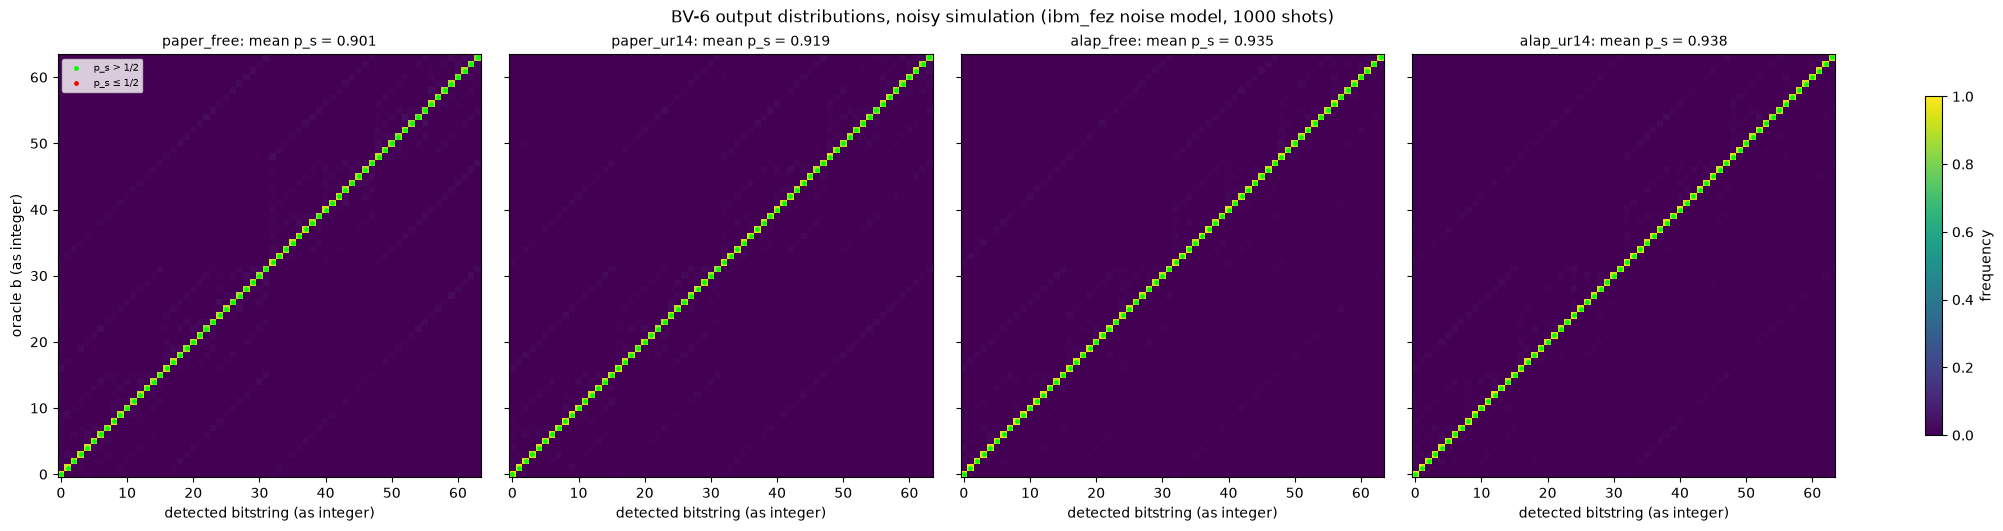

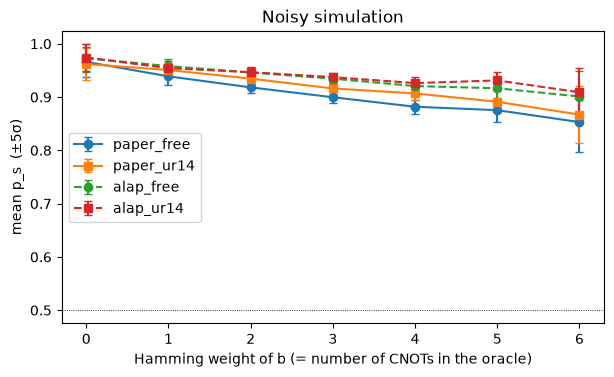

In [15]:
SHOTS = 1000

noisy_sim = AerSimulator.from_backend(backend)
noisy = split_by_variant(noisy_sim.run(ALL_CIRCUITS, shots=SHOTS, seed_simulator=SEED).result().get_counts())
noisy_ps = ps_table(noisy, SHOTS)
display(summary_table(noisy_ps, SHOTS).round(4))
plot_fig2(noisy, noisy_ps, f"BV-6 output distributions, noisy simulation ({backend.name} noise model, {SHOTS} shots)",
          "bv6_fig2_noisy_sim.png")
plot_ps_vs_weight(noisy_ps, SHOTS, "Noisy simulation")

### 7b. QPU budget check

IBM bills QPU time per shot. Each shot costs roughly (circuit duration + repetition delay), plus a few seconds of
per-job overhead. The repetition delay dominates: ~250 µs against ~3 µs of circuit. If `CALIBRATION_JOB_ID` is set
(Experiment 1's free+UR-14 job, 14 circuits × 2000 shots), the cell also reads that job's **actual** billed usage
and scales it to this batch. The larger of the two estimates must fit under `QPU_BUDGET_SECONDS`, and the
Open Plan allows ~600 s per 28 days.

In [16]:
QPU_BUDGET_SECONDS = 240
CALIBRATION_JOB_ID = "dapdo9gr7bnc73b38qeg"   # Experiment 1 (free + UR-14 on ibm_fez); None to skip

rep_delay = getattr(backend.configuration(), "default_rep_delay", 250e-6) or 250e-6
rep_delay = rep_delay * 1e-6 if rep_delay > 1e-2 else rep_delay  # tolerate a value reported in us
total_shots = SHOTS * len(ALL_CIRCUITS)
model_estimate = sum(SHOTS * (c.estimate_duration(target, unit="s") + rep_delay) for c in ALL_CIRCUITS) + 5.0
estimates = {"model: shots x (duration + rep_delay) + 5 s": model_estimate}

if service is not None and CALIBRATION_JOB_ID:
    try:
        ref = service.job(CALIBRATION_JOB_ID)
        ref_seconds = float(ref.usage())
        ref_shots = sum(pub.data.c.num_shots for pub in ref.result())
        estimates[f"scaled from job {CALIBRATION_JOB_ID} ({ref_seconds:.1f} s / {ref_shots} shots)"] = (
            ref_seconds / ref_shots * total_shots)
    except Exception as exc:
        print(f"(Could not read calibration job: {exc})")

for name, est in estimates.items():
    print(f"{est:7.1f} s   {name}")
QPU_ESTIMATE = max(estimates.values())
budget_ok = QPU_ESTIMATE <= QPU_BUDGET_SECONDS
print(f"\n{len(ALL_CIRCUITS)} circuits x {SHOTS} shots = {total_shots:,} shots -> estimate {QPU_ESTIMATE:.1f} s "
      f"vs budget {QPU_BUDGET_SECONDS} s: {'OK' if budget_ok else 'OVER BUDGET: lower SHOTS'}")

   69.6 s   model: shots x (duration + rep_delay) + 5 s
   82.3 s   scaled from job dapdo9gr7bnc73b38qeg (9.0 s / 28000 shots)

256 circuits x 1000 shots = 256,000 shots -> estimate 82.3 s vs budget 240 s: OK


### 7c. Real hardware

**This cell spends QPU quota.** Before setting `SUBMIT = True`:
1. set `USE_FAKE_BACKEND = False` in §0 and rerun everything above, so the circuits are built against the live
   calibration;
2. check that the correctness gates (§5c) pass and the budget (§7b) prints OK.

All 256 circuits go in **one** `SamplerV2` job. They are already scheduled and padded, so Runtime's own DD is
explicitly **disabled**: the only DD on the chip is our UR-14. Twirling is off too. The job ID is printed, and the
counts are saved to `results/` as soon as they arrive.

In [17]:
SUBMIT = True

job = None
if SUBMIT:
    if USE_FAKE_BACKEND:
        raise RuntimeError("Set USE_FAKE_BACKEND = False and rebuild the circuits against the live backend first.")
    if not budget_ok:
        raise RuntimeError("Over budget: lower SHOTS.")
    from qiskit_ibm_runtime import SamplerV2

    sampler = SamplerV2(mode=backend)
    sampler.options.dynamical_decoupling.enable = False  # our UR-14 only
    sampler.options.twirling.enable_gates = False
    sampler.options.twirling.enable_measure = False
    job = sampler.run(ALL_CIRCUITS, shots=SHOTS)
    print(f"Submitted job {job.job_id()} on {backend.name}: {len(ALL_CIRCUITS)} circuits x {SHOTS} shots")
else:
    print("SUBMIT is False: no hardware job submitted.")

Submitted job dar140akqcdc73abf3b0 on ibm_fez: 256 circuits x 1000 shots


### 7d. Collect results (or reload a finished job by ID)

`job.result()` blocks until the job finishes, and that includes queue time. If the kernel restarted, put the
printed ID in `HW_JOB_ID` and rerun §0–§3 with `USE_FAKE_BACKEND = False`. The same `SEED` and `LAYOUT` rebuild
the circuit list, so counts line up by position again.

In [18]:
HW_JOB_ID = None   # e.g. "d3abc..." to reload a finished job

hw = None
if job is None and HW_JOB_ID and service is not None:
    job = service.job(HW_JOB_ID)
if job is not None:
    result = job.result()
    hw_counts = [result[i].data.c.get_counts() for i in range(len(ALL_CIRCUITS))]
    hw = split_by_variant(hw_counts)
    out = RESULTS_DIR / f"bv6_fig1_{backend.name}_{job.job_id()}.json"
    out.write_text(json.dumps({
        "job_id": job.job_id(), "backend": backend.name, "shots": SHOTS, "seed": SEED, "layout": list(LAYOUT),
        "saved_utc": datetime.now(timezone.utc).isoformat(), "variants": VARIANTS, "oracles": ORACLES,
        "counts": hw}, indent=1))
    print(f"Saved counts to {out}")
else:
    print("No hardware job to collect.")

Saved counts to results\bv6_fig1_ibm_fez_dar140akqcdc73abf3b0.json


,mean p_s,±5σ,min p_s,oracles with p_s > 1/2
variant,,,,
paper_free,0.7829,0.0081,0.693,64
paper_ur14,0.8209,0.0075,0.754,64
alap_free,0.8516,0.0070,0.750,64
alap_ur14,0.8485,0.0070,0.750,64


Paper (BV-6, Fig. 2): 59.9% without DD -> 74.7% with DD


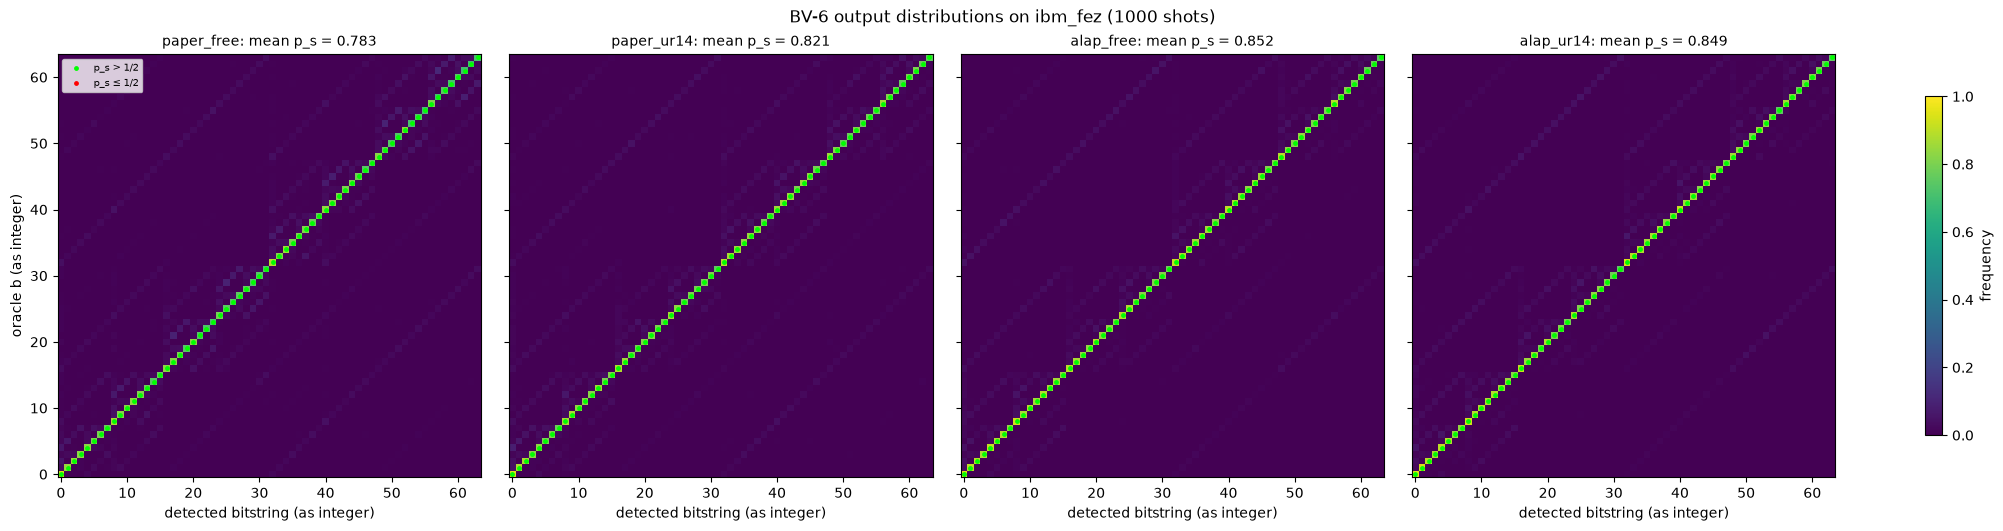

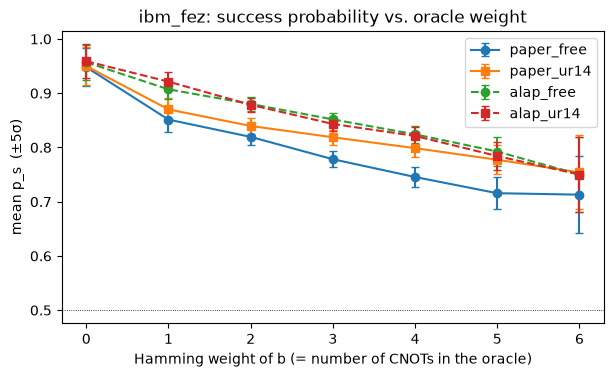

,paper_free,paper_ur14,alap_free,alap_ur14
weight,,,,
0,0.948,0.950,0.957,0.959
1,0.851,0.870,0.907,0.921
2,0.819,0.840,0.880,0.879
3,0.778,0.819,0.852,0.843
4,0.746,0.799,0.824,0.821
5,0.716,0.777,0.792,0.784
6,0.713,0.754,0.750,0.750


In [19]:
if hw is not None:
    hw_ps = ps_table(hw, SHOTS)
    display(summary_table(hw_ps, SHOTS).round(4))
    print(f"Paper (BV-6, Fig. 2): {PAPER_REF['without DD']:.1%} without DD -> {PAPER_REF['with DD']:.1%} with DD")
    plot_fig2(hw, hw_ps, f"BV-6 output distributions on {backend.name} ({SHOTS} shots)", f"bv6_fig2_{backend.name}.png")
    plot_ps_vs_weight(hw_ps, SHOTS, f"{backend.name}: success probability vs. oracle weight")
    display(hw_ps.groupby("weight")[VARIANTS].mean().round(3))

## 8. How to read the outcome

* **Correctness**: §5c is the proof that the pipeline computes BV. Every circuit returns $b$ with certainty
  when there is no noise, DD included.
* **Does DD help?** Compare `paper_ur14` against `paper_free` oracle by oracle. The gap should grow with
  Hamming weight, because more CNOTs mean longer waits in superposition. Then compare the two schedules:
  * The `paper` schedule is closest to the paper's experiment. It creates the long superposition gaps that DD
    needs, and the §4 coverage table shows that UR-14 fills most of that time.
  * `alap` hides most of the waiting in $|0\rangle$ instead. That is the other way to fight idle errors (don't
    be in superposition while waiting), and it is one likely reason Experiment 1 (ALAP) saw no DD effect.
* **Why the numbers can differ from the paper**:
  * Fez is a Heron processor. Its CZ takes 84 ns against ~300–500 ns for the paper's Falcon CNOTs, so the idle
    gaps are much shorter.
  * Its X pulse (24 ns) is a larger fraction of each gap.
  * Its ZZ crosstalk is lower by design, and ZZ crosstalk was one of the main errors DD removed on Falcon.
  * The paper also used 32 000 shots per oracle and its own CNOT-efficient ancilla-swap router.